# Customer Churn: EDA and Model

Dataset: IBM Telco Customer Churn (7,043 customers, 21 columns). `Churn = Yes` means the customer left in the last month.

Goal: find which customers are likely to leave, so the company can contact them before they do.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
IMG = "../images/"

df = pd.read_csv("../data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` is stored as text. Converting it shows 11 blank values.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


All 11 have `tenure = 0`, so they are brand new customers who haven't been billed yet. Filling with 0 makes sense instead of dropping them.

In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
print("overall churn rate: %.1f%%" % (df["churn_flag"].mean() * 100))

overall churn rate: 26.5%


About 26.5% of customers churned. The classes are imbalanced (roughly 3:1), so accuracy alone will be misleading later.

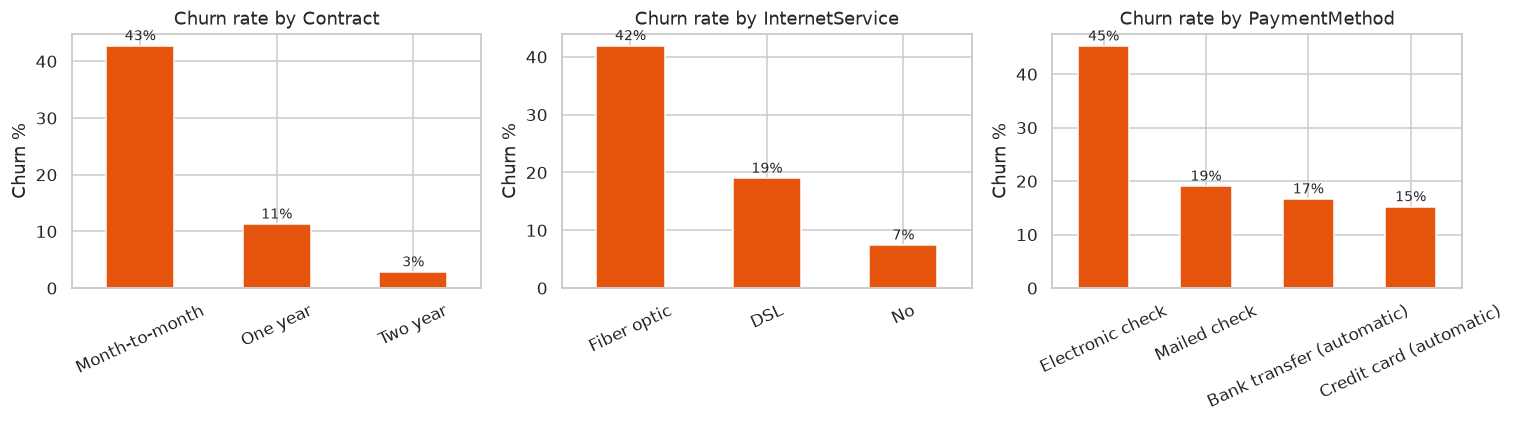

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["churn_flag"].mean().sort_values(ascending=False) * 100
    rate.plot(kind="bar", ax=ax, color="#e6550d")
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn %")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
    for i, v in enumerate(rate):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(IMG + "churn_by_category.png")
plt.show()

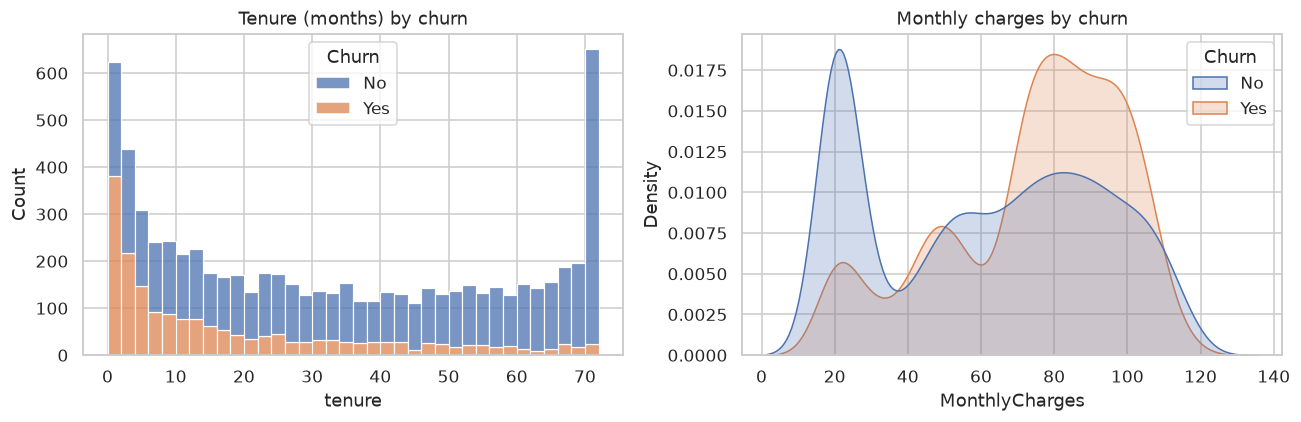

tenure_group
0-6      52.9
7-12     35.9
13-24    28.7
25-48    20.4
49-72     9.5
Name: churn_flag, dtype: float64

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=axes[0])
axes[0].set_title("Tenure (months) by churn")
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", common_norm=False, fill=True, ax=axes[1])
axes[1].set_title("Monthly charges by churn")
plt.tight_layout()
plt.savefig(IMG + "tenure_charges.png")
plt.show()

df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
(df.groupby("tenure_group", observed=True)["churn_flag"].mean() * 100).round(1)

In [7]:
# a few more yes/no services
cols = ["OnlineSecurity", "TechSupport", "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents"]
summary = []
for c in cols:
    for val, g in df.groupby(c):
        summary.append({"feature": c, "value": val, "customers": len(g), "churn_%": round(g["churn_flag"].mean() * 100, 1)})
pd.DataFrame(summary)

,feature,value,customers,churn_%
0,OnlineSecurity,No,3498,41.8
1,OnlineSecurity,No internet service,1526,7.4
2,OnlineSecurity,Yes,2019,14.6
3,TechSupport,No,3473,41.6
4,TechSupport,No internet service,1526,7.4
5,TechSupport,Yes,2044,15.2
6,PaperlessBilling,No,2872,16.3
7,PaperlessBilling,Yes,4171,33.6
8,SeniorCitizen,0,5901,23.6
9,SeniorCitizen,1,1142,41.7


**What stands out**
- **Month-to-month contracts churn at about 43%**, two-year contracts at about 3%.
- New customers are the riskiest: around half of customers in their first 6 months leave.
- Fiber optic users and people paying by electronic check churn much more.
- Customers without online security or tech support churn almost 3x more than those who have it (about 42% vs 15%).
- Churners have higher monthly charges on average.

## Model

Plan: one-hot encode the categories, scale the 3 numeric columns, then compare a few models with 5-fold cross validation.
I kept 20% of the data aside as a test set and only used it at the end.

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
            "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]

X = df[num_cols + cat_cols]
y = df["churn_flag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced", random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    fitted[name] = pipe
    rows.append({
        "model": name,
        "cv_auc": round(cv_auc, 3),
        "test_auc": round(roc_auc_score(y_test, proba), 3),
        "accuracy": round(accuracy_score(y_test, pred), 3),
        "precision": round(precision_score(y_test, pred), 3),
        "recall": round(recall_score(y_test, pred), 3),
        "f1": round(f1_score(y_test, pred), 3),
    })

results = pd.DataFrame(rows)
results

,model,cv_auc,test_auc,accuracy,precision,recall,f1
0,Logistic Regression,0.846,0.842,0.806,0.657,0.559,0.604
1,Logistic Regression (balanced),0.846,0.842,0.738,0.504,0.783,0.614
2,Random Forest,0.845,0.842,0.762,0.536,0.773,0.633
3,Gradient Boosting,0.844,0.839,0.803,0.664,0.524,0.586


All four models end up around **0.84 ROC-AUC**, so the fancier models don't really win here.

I picked **Logistic Regression with balanced class weights**:
- same AUC as the others
- much higher recall than plain logistic regression (it catches more of the customers who actually leave). For churn, missing a leaving customer costs more than calling one who would have stayed.
- easy to explain: every feature has a coefficient
- small enough to run inside a web page for the demo

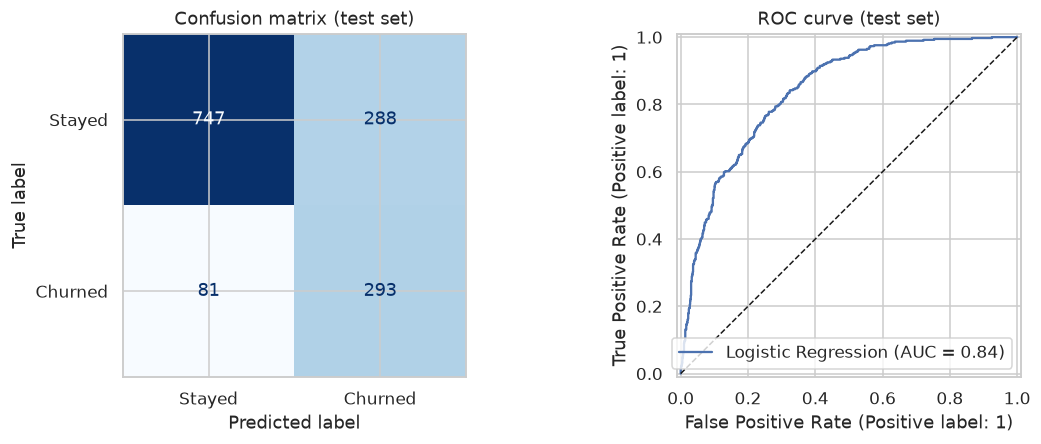

In [10]:
best = fitted["Logistic Regression (balanced)"]
proba = best.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Churned"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test set)")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name="Logistic Regression")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curve (test set)")
plt.tight_layout()
plt.savefig(IMG + "model_results.png")
plt.show()

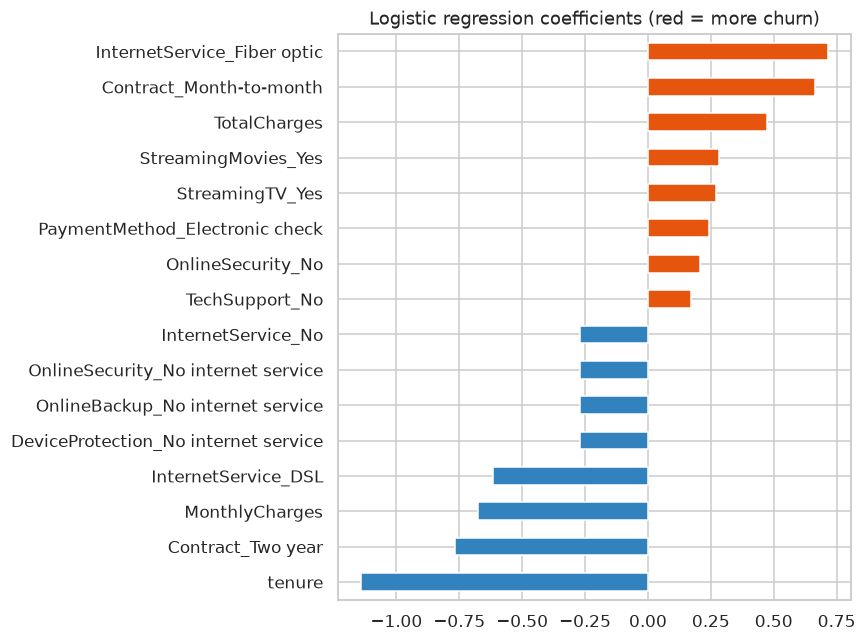

In [11]:
# which features push churn up or down?
names = best.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(best.named_steps["model"].coef_[0], index=names)
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([coefs.nlargest(8), coefs.nsmallest(8)]).sort_values()

ax = top.plot(kind="barh", figsize=(8, 6), color=["#3182bd" if v < 0 else "#e6550d" for v in top])
ax.set_title("Logistic regression coefficients (red = more churn)")
plt.tight_layout()
plt.savefig(IMG + "coefficients.png")
plt.show()

Note: `MonthlyCharges` comes out negative even though churners pay more on average. That's because it is strongly correlated with `TotalCharges`, `tenure` and the fiber/streaming columns, which already carry the price effect. With correlated features I shouldn't read one coefficient on its own. Contract type, tenure and internet type are the safe conclusions here.

In [12]:
# what if the retention team can only call the top 20% riskiest customers?
test = X_test.copy()
test["proba"] = proba
test["churned"] = y_test.values
top20 = test.nlargest(int(len(test) * 0.2), "proba")
print("customers called:", len(top20))
print("churners among them: %d of %d total churners (%.1f%%)" % (top20["churned"].sum(), test["churned"].sum(),
      top20["churned"].sum() / test["churned"].sum() * 100))
print("hit rate in top 20%%: %.1f%% vs %.1f%% overall" % (top20["churned"].mean() * 100, test["churned"].mean() * 100))

customers called: 281
churners among them: 186 of 374 total churners (49.7%)
hit rate in top 20%: 66.2% vs 26.5% overall


## Conclusion

- The model reaches about **0.84 ROC-AUC** on unseen customers and catches about **78% of churners** at the 0.5 threshold.
- If the retention team only calls the 20% highest-risk customers, they reach **about half of all churners (49.7%)**, and 66% of the people they call are real churners, compared to 26.5% if they called at random.
- Biggest churn drivers: month-to-month contract, short tenure, fiber optic internet and electronic check payment. Long contracts and add-ons like online security push risk down.
- Business idea: offer new month-to-month customers a discount to switch to a 1-year contract, and bundle tech support / online security for fiber customers.

The final model is trained in `src/train.py`.